In [2]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Demonstrator 1 - Diffusive and dispersive schemes for a gaussian signal

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [405]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00



cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_gauss_ubs.*
rm CANAL_gauss_fct2.*
rm CANAL_gauss_fct4.*

chmod -R a+x /"$DIR"/demo_gauss/

bash /"$DIR"/demo_gauss/gauss_istate.sh "$DIR"
bash /"$DIR"/demo_gauss/gauss_cfg.sh "$DIR"
bash /"$DIR"/demo_gauss/lambda_run.sh "$DIR" "25 50 100 200"
    

106a107
>             pts(:,:,jk,jp_sal) = 30._wp+5._wp*EXP( -0.5_wp *glamt(:,:)**2 / rn_lambda**2 )
Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
Compilation form : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
-e 



You are compiling an existing configuration EXP42 with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for EXP42

Process is interrupted.


In [3]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''


In [4]:
lambda_list = [25, 50, 100, 200]
scheme_list = ['ubs', 'fct2', 'fct4']

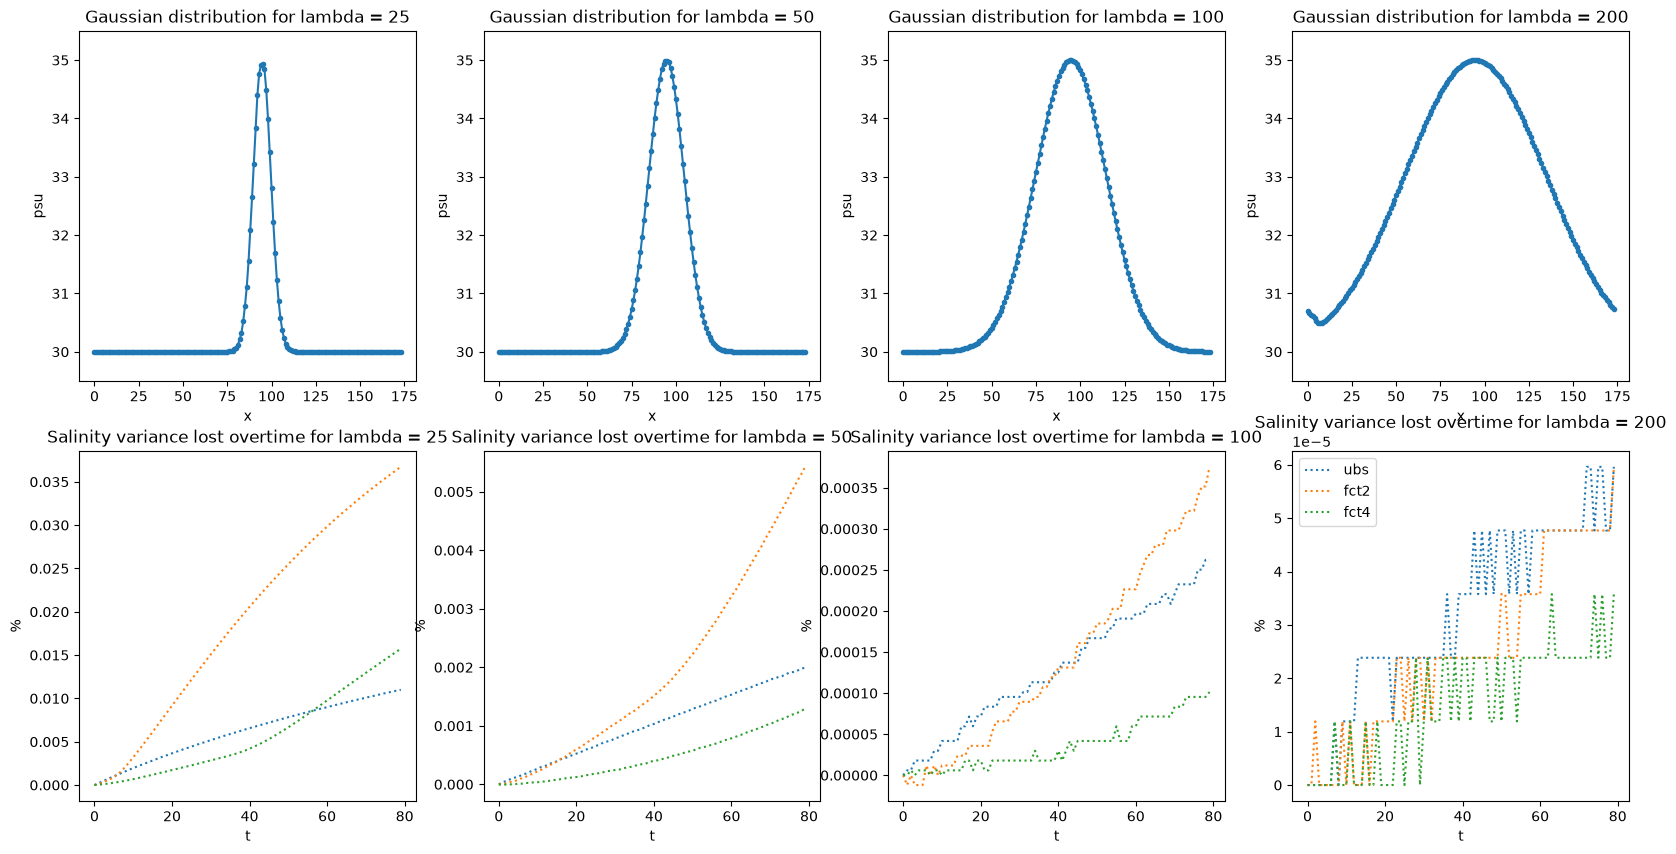

In [5]:
fig_salt2c, axes_salt2c = plt.subplots(2, len(lambda_list), figsize=(20,10)) 

for i, l in enumerate(lambda_list):
        for scheme in scheme_list :
            dataset = xr.open_dataset(rep+'CANAL_gauss_'+scheme+'.'+str(l)+'_all_grid.nc', decode_times=False)
            s2c = dataset['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
            s2c = np.array(s2c)
            tot = s2c[0]
            data = (1-s2c/s2c[0])*100
            time = np.arange(s2c.shape[0])
            axes_salt2c[1][i].plot(time,  data, ':', label = scheme)#trace le pourcentage 1-le ratio sur la valeur initiale
            #axes_salt2c[1][i].set_ylim(0,0.035)
            axes_salt2c[1][i].set_title(f"Salinity variance lost overtime for lambda = {l}")
            axes_salt2c[1][i].set_xlabel('t')
            axes_salt2c[1][i].set_ylabel('%')
        gauss = dataset['soce'].isel(time_counter=0, y_grid_T = 50, deptht=0)
        x = np.arange(gauss.shape[0])
        axes_salt2c[0][i].plot(x, gauss, '.-')
        axes_salt2c[0][i].set_title(f"Gaussian distribution for lambda = {l}")
        axes_salt2c[0][i].set_ylim(29.5,35.5)
        axes_salt2c[0][i].set_xlabel('x')
        axes_salt2c[0][i].set_ylabel('psu')
plt.legend()


### Analysis of the outcome

In [6]:
cen2 = xr.open_dataset(rep+'CANAL_gauss_cen2.100_all_grid.nc', decode_times=False)
ubs = xr.open_dataset(rep+'CANAL_gauss_ubs.100_all_grid.nc', decode_times=False)
fct2 = xr.open_dataset(rep+'CANAL_gauss_fct2.100_all_grid.nc', decode_times=False)
fct4 = xr.open_dataset(rep+'CANAL_gauss_fct4.100_all_grid.nc', decode_times=False)

## Comparative plots

In [7]:
gauss_0 = xr.open_dataset(rep+'CANAL_gauss_traadvOFF.100_all_grid.nc', decode_times=False)
gauss_0 =gauss_0.soce.isel(y_grid_T = 50, time_counter=0, deptht=0)

v= 0.5
dx = 5000
ref = []

for t in range (80):
    ref.append(np.roll(gauss_0, shift=v*86400*(t+1)/dx))
    


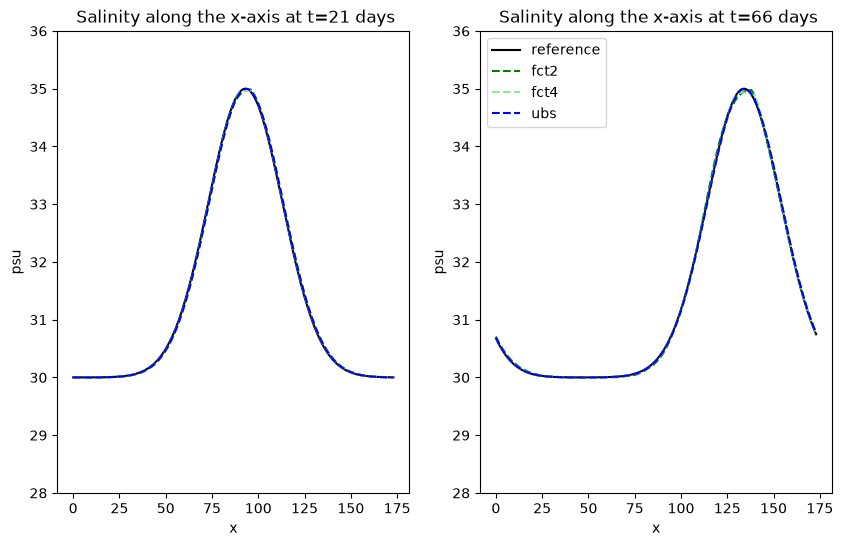

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10,6))

ax[0].plot(np.arange(len(ref[0])), ref[20], color ='black', label ='reference')
ax[0].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_ylim(28,36)
ax[0].set_title(f' Salinity along the x-axis at t=21 days')

ax[1].plot(np.arange(len(ref[0])), ref[65], color ='black', label ='reference')
ax[1].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_ylim(28,36)
ax[1].set_title(f' Salinity along the x-axis at t=66 days')

plt.legend()


In [16]:
gauss_0 = xr.open_dataset(rep+'CANAL_gauss_traadvOFF.100_all_grid.nc').sssgrad.isel(y_grid_T = 50, time_counter = 0)

ref_grad = []

for t in range (80):
    ref_grad.append(np.roll(gauss_0, shift=v*86400*(t+0.5)/dx)) 
"""ce 0.5 me pose probleme, cela veut dire que soit la sortie 
        est prise en milieu de journee pas en fin de journee comme on avait convenu
        normalement ce n'est pas la moyenne de la journee c'est sur car j'ai bien verifie 
        dans def_field qu'on etait en operation=instant"""


"ce 0.5 me pose probleme, cela veut dire que soit la sortie \n        est prise en milieu de journee pas en fin de journee comme on avait convenu\n        normalement ce n'est pas la moyenne de la journee c'est sur car j'ai bien verifie \n        dans def_field qu'on etait en operation=instant"

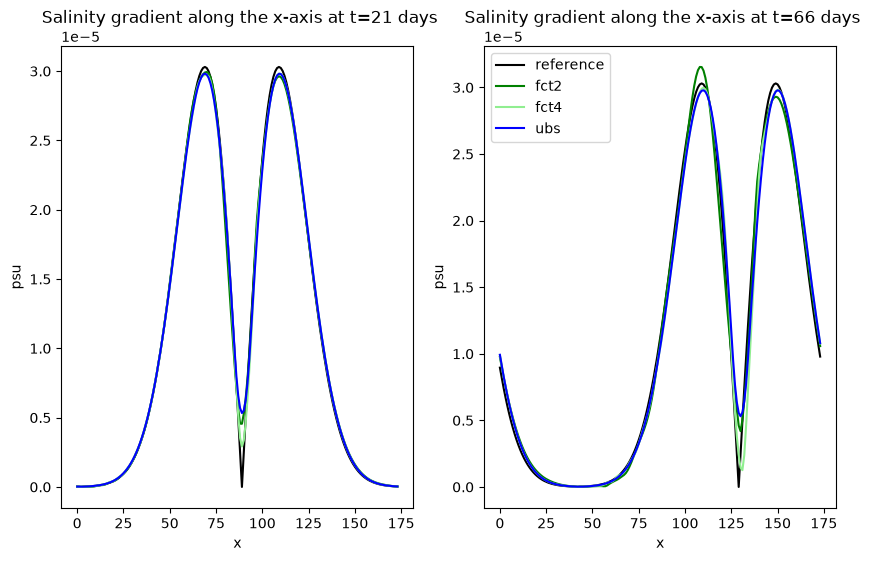

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10,6))

ax[0].plot(np.arange(len(ref_grad[0])), ref_grad[20], color ='black', label ='reference')
ax[0].plot(np.arange(fct2['sssgrad'].shape[2]), fct2['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['sssgrad'].shape[2]), fct4['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['sssgrad'].shape[2]), ubs['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_title(f' Salinity gradient along the x-axis at t=21 days')

ax[1].plot(np.arange(len(ref_grad[0])), ref_grad[65], color ='black', label ='reference')
ax[1].plot(np.arange(fct2['sssgrad'].shape[2]), fct2['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['sssgrad'].shape[2]), fct4['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['sssgrad'].shape[2]), ubs['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_title(f' Salinity gradient along the x-axis at t=66 days')

plt.legend()

In [59]:
cen2.close()
ubs.close()
fct2.close()

In [124]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

bash /"$DIR"/demo_gauss/end_gauss.sh "$DIR"

+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ DIR_PARENT=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90
+ TMP=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.tmp
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 ']'
+ awk '
/pts\(:,:,jk,jp_sal\).*EXP.*rn_lambda/ {next}
{print}
' /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90
+ diff /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.tmp
+ cp /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
+ mv /Users/jbuisson

Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak


+ cd /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
+ echo Compiling
+ ./makenemo -r CANAL -n EXP42


Compiling
-e 



You are compiling an existing configuration EXP42 with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for EXP42

/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC content is linked to /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK

--------------------------------------------------------------------------------
Compilation
--------------------------------------------------------------------------------

Build command started on Thu Oct  8 15:16:39 2026.
->Parse configuration: start
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/bld.cfg
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/arch_nemo.fcm
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/cpp.fcm
->Parse configuration: 1 second
->Setup destination: start
De

Use of uninitialized value in numeric gt (>) at /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/ext/FCM/bin/../lib/Fcm/BuildTask.pm line 176.


No. of pre-processed file: 1
->Pre-process: 0 second
->Scan dependency: start
No. of file scanned for dependency: 1
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/Makefile: updated
->Scan dependency: 0 second
->Generate Fortran interface: start
->Generate Fortran interface: 0 second
->Make: start
mpif90-mpich-gcc15 -o usrdef_istate.o -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/inc -fdefault-real-8 -march=native -O2 -fno-expensive-optimizations -funroll-all-loops -fcray-pointer -ffree-line-length-none -fallow-argument-mismatch -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/inc -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/include -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/include -c /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/ppsrc/nemo/usrdef_istate.f90
mpif90-mpich-gcc15 -o restart.o -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/inc -fdefault-real-8 -march=native 

ar: creating archive /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(cyclone.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(defprec.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(ioipsl.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(obs_const.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(par_kind.o) has no symbols
/Library/Developer/CommandLineTools

mpif90-mpich-gcc15 -o nemo.exe /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/obj/nemo.o -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/lib -l__fcm__nemo -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/lib -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/lib -lxios -lstdc++ -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lnetcdff -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lnetcdf -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lhdf5_hl -lhdf5 -L/opt/local/lib -lcurl  -lz  -lm
->Make: 113 seconds
->TOTAL: 114 seconds
Build command finished on Thu Oct  8 15:18:33 2026.

--------------------------------------------------------------------------------
Compilation successful
------------------------------------------------------------------